# Notebook 7 – Outlier Analysis

An outlier is a data point that differs significantly from the general pattern of the other observations in a dataset

For example, consider the monthly salaries of employees:

25000, 28000, 30000, 32000, 35000, 250000

Here, ₹2,50,000 is much higher than the other salaries, so it may be an outlier

However, it could be a genuine salary for a senior manager rather than an error

### Why do outliers occur?

- Data-entry errors: Salary entered as ₹5,00,000 instead of ₹50,000.
- Measurement errors: A faulty sensor records an incorrect temperature.
- Natural variation: A customer spends much more than other customers.
- Rare events: An unusually large insurance claim.
- Data processing errors: Incorrect unit conversion or duplicate calculations.
- Population differences: Senior employees earn more than junior employees

### Types of Outliers

### Point (Global) Outlier

One observation is unusual compared with the overall dataset.

Example: An employee earns ₹10 lakh per month while most earn ₹25,000–₹60,000.

### Contextual Outlier

An observation is unusual in a particular context, such as time or location.

Example: A temperature of 35°C may be normal in summer but unusual in winter.

### Collective Outlier

A group or sequence of observations is unusual, even if individual values appear normal.

Example: A sequence of unusual transactions may indicate fraudulent activity


### Univariate vs. Multivariate Outliers

Type	           Meaning	                              Example

Univariate	    Unusual value in one feature        	Salary is exceptionally high

Multivariate	Unusual combination of features  	   A very young employee has an unusually high salary and senior-level job title

A value can be normal when examined individually but unusual when combined with other features.

## Detection techniques

### IQR Method (Interquartile Range)

The IQR method identifies unusually low or high values using the middle 50% of the data


The IQR method is used to identify potential outliers in a dataset.

**Formulas:**


The key formulas are:

$$
IQR = Q_3 - Q_1
$$

$$
\text{Lower Bound} = Q_1 - 1.5 \times IQR
$$

$$
\text{Upper Bound} = Q_3 + 1.5 \times IQR
$$

**Where:**

- $Q_1$: 25th percentile (First Quartile).
- $Q_3$: 75th percentile (Third Quartile).
- $IQR$: Interquartile Range.

**Interpretation:**

- Values below the Lower Bound are potential lower outliers.
- Values above the Upper Bound are potential upper outliers.
- Values within the bounds are not flagged as outliers by the IQR method.


In [1]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 40000, 42000, 45000, 250000]
})

Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Salary"] < lower_bound) |
    (df["Salary"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("\nPotential Outliers:")
print(outliers)

Q1: 30500.0
Q3: 41500.0
IQR: 11000.0
Lower Bound: 14000.0
Upper Bound: 58000.0

Potential Outliers:
   Salary
9  250000


Interpretation: Any salary outside the calculated bounds is flagged for investigation. This does not automatically mean the salary is incorrect

### Z-Score Method

The Z-score measures how many standard deviations a value lies above or below the mean



**Formula:**


\[
z = \frac{x - \mu}{\sigma}
\]


**Where:**

- \(x\): Individual observation.
- \(\mu\): Mean of the feature.
- \(\sigma\): Standard deviation of the feature.

**Interpretation:**

- \(z = 0\): The observation equals the mean.
- \(z > 0\): The observation is above the mean.
- \(z < 0\): The observation is below the mean.
- \(|z| > 3\): The observation is commonly flagged as a potential outlier.

**Note:** A Z-score identifies unusual values; it does not automatically mean they are errors.


In [2]:
df["Z_Score"] = (
    df["Salary"] - df["Salary"].mean()
) / df["Salary"].std()

outliers_zscore = df[
    df["Z_Score"].abs() > 3
]

print(outliers_zscore)

Empty DataFrame
Columns: [Salary, Z_Score]
Index: []


### Box Plot

A box plot helps visualize the median, quartiles, spread and potential outliers

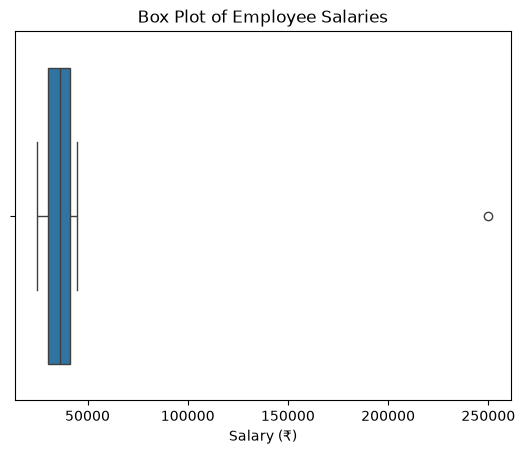

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["Salary"])
plt.title("Box Plot of Employee Salaries")
plt.xlabel("Salary (₹)")
plt.show()

What to observe:

- Points far away from the general pattern
- Unusual combinations of age and salary
- Observations that do not follow the usual relationship between the features
  
Note that an isolated point is not necessarily incorrect

### Detect outliers in numerical columns

In [4]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

outlier_summary = []

for col in numeric_cols:
    series = df[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (series < lower) | (series > upper)

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(mask.sum()),
        "Outlier Percentage": (
            mask.sum() / len(series) * 100
            if len(series) else 0
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Salary,14000.00000,58000.000000,1,10.0
1,Z_Score,-0.62237,0.021966,1,10.0


### Multivariate Outlier Detection

Multivariate analysis investigates whether an observation is unusual across multiple features at the same time.

For example, a customer's income and spending may each be normal individually, but their combination may be unusual

### Pair Plot

In [10]:
sns.pairplot(
    df[["Age"]],
    diag_kind="hist"
)

plt.show()

KeyError: "None of [Index(['Age'], dtype='str')] are in the [columns]"

In [11]:
print(list(df.columns))

['Salary', 'Z_Score']
